# 18 — Skenario 3 (S3): rs-fMRI + sMRI + Fenotipik dengan GATv2 + Node-Attention Pooling

**Dataset:** ABIDE I + ABIDE II (turunan DCAN), 1.638 subjek, 34 situs
**Modalitas:** rs-fMRI + sMRI + data fenotipik (usia, jenis kelamin, FIQ)
**Model:** model usulan yang **sama** dengan S1–S2 (notebook 16–17), ditambah **cabang ketiga** untuk fenotipik


| | |
| :--- | :--- |
| **Masukan** | `data/processed/kohort_dcan.csv` (1.638 subjek, fold `fold_gabungan`, notebook 09) · seperti S2 + fenotipik usia, jenis kelamin, FIQ (`kohort_dcan.csv`, notebook 05/09) · probabilitas baseline LR `result/tabel/22_cache/C3_gab_tangent_<atlas>.npz` (dijelaskan di notebook 14) · prediksi skenario sebelumnya `result/tabel/26_S2_prediksi.csv (notebook 17)` |
| **Keluaran** | `result/tabel/27_S3_*.csv` (hasil per run, per fold, prediksi per subjek, uji McNemar) · `result/metrics/S3_ringkasan.json` · `result/figure/27_*.png` · cache pelatihan `result/tabel/27_cache_5run/` |

---

## Posisi S3 dalam rangkaian skenario

| Skenario | Notebook | Informasi yang dipakai |
| :---: | :---: | :--- |
| S1 | 16 | rs-fMRI: graf otak (fitur simpul = FC tangent) + cabang linear FC tangent 3 atlas |
| S2 | 17 | S1 + sMRI: 5 morfometri per parcel ditambahkan ke fitur simpul graf |
| **S3** | **18 (ini)** | **S2 + fenotipik** (usia, jenis kelamin, FIQ) sebagai cabang ketiga |
| S4 | 19 | **sama dengan S3**; hyperparameter dicari dengan *Optuna* di setiap fold |

**Pertanyaan S3:** apakah data **fenotipik** (non-citra) menambah kemampuan model dibanding rs-fMRI + sMRI (S2)? Data ini bisa melengkapi citra dengan dua cara:
1. **informasi langsung**: rata-rata FIQ kelompok ASD lebih rendah daripada kontrol;
2. **konteks**: pola FC dan morfometri berubah dengan usia dan berbeda antara laki-laki dan perempuan, jadi model bisa menilai citra sesuai usia dan jenis kelamin subjek.

### Apa yang berubah dari S2, dan apa yang tidak

| Bagian | S2 | S3 |
| :--- | :--- | :--- |
| Cabang graf (FC + morfometri per parcel) | ada | sama |
| Cabang linear (FC tangent 3 atlas) | ada | sama |
| **Cabang fenotipik** | – | **baru: MLP kecil (4 fitur → 64)** |
| Fusi atensi | 2 cabang | **3 cabang**, bobot β dihitung per subjek |
| Model, hyperparameter, fold, seed, 5 run | – | **sama persis** |

Pola ini disebut *late fusion*: data fenotipik diproses dalam cabang terpisah lalu digabung setelah setiap cabang menghasilkan ringkasannya. Penggabungan fitur fenotipik dengan citra seperti ini sudah dipakai di penelitian ASD sebelumnya. Pendekatan lain, misalnya graf populasi, memakai fenotipik sebagai **bobot sisi** antar subjek. Di sini fenotipik tetap menjadi fitur subjek itu sendiri.

### Ekspektasi yang jujur

Pengecekan cepat dengan Logistic Regression pada **fenotipik saja** (fold yang sama) memberi ±58% / AUC ±64. Jadi informasinya ada tetapi lemah, dan sebagian bisa tumpang tindih dengan citra. Kenaikan yang wajar diharapkan kecil (±0–1,5 poin). Kalau S3 ≈ S2, itu berarti informasi fenotipik sudah tercakup oleh citra.

---

## Arsitektur model

```
 graf otak HCP-360 (379 FC + 5 sMRI per parcel) ──► CABANG GRAF: GATv2 + node-attention pooling ──┐
                                                                                                   │   ┌──────────────┐
 FC tangent 3 atlas (±154 ribu nilai) ────────────► CABANG LINEAR: PCA penuh → lapisan linear ─────┼──►│ FUSI ATENSI  │──► MLP ──► [Kontrol, ASD]
                                                                                                   │   │ (β, 3 cabang)│
 log usia, jenis kelamin, FIQ, FIQ kosong ────────► CABANG FENOTIPIK: MLP (4 → 64) ────────────────┘   └──────────────┘
                              setiap cabang juga punya kepala klasifikasi bantu (deep supervision)
```

Penjelasan komponen dan alasan desain ada di notebook 16. Desain ini **dikunci untuk S1–S4**.

---

## Protokol

Sama persis dengan notebook 16–17: statistik fitur (termasuk median FIQ untuk pengisian nilai kosong) dari data latih setiap fold, *class weight* seimbang, *early stopping* pada potongan validasi 15% dari data latih, ambang 0,5, fold `fold_gabungan`, **5 run** (seed 0–4, sama dengan S1–S2). Karena seed sama, perbandingan S2 vs S3 per run bersifat **berpasangan**.

## Lama proses

Penyiapan fitur ±1,5 menit per fold, RAM ±4–5 GB. **Tutup kernel notebook lain sebelum menjalankan.** Pelatihan **±2–2,5 jam** (5 fold × 5 run). Hasil setiap fold disimpan ke `result/tabel/27_cache_5run/`; kalau terhenti, jalankan ulang dan fold yang sudah selesai akan dilewati.

## 1. Persiapan

In [1]:
import gc
import sys
import json
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy import stats
from sklearn.metrics import confusion_matrix, roc_curve
from IPython.display import display
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
while not (ROOT / "data").exists():
    ROOT = ROOT.parent
sys.path.append(str(ROOT))
import importlib
import src.usulan
importlib.reload(src.usulan)          # selalu pakai versi terbaru src/usulan.py walau kernel belum di-restart
from src.metrics import hitung_metrik
from src.usulan import (DEVICE, ModelUsulan, buat_graf, fitur_linear_pca, fitur_simpul_baris, jalankan_cv_usulan, sisi_topk)

# ----- Parameter skenario (ditetapkan sebelum pelatihan) -----
SKENARIO = "S3"
ATLAS = {"gordon2014": 352, "hcp2016": 379, "markov2012": 205}   # jumlah ROI setiap atlas DCAN
ATLAS_GRAF = "hcp2016"
N_SIMPUL = 360                     # parcel korteks HCP (berada di urutan awal time series DCAN)
K_SISI = 20                        # setiap simpul dihubungkan ke 20 tetangga dengan |korelasi| terbesar
HIPER_MODEL = dict(hidden=64, n_layer=2, heads=4, dropout=0.5, dropout_input=0.2, dropedge=0.2, dropout_linear=0.2, bobot_bantu=0.5)
CFG_LATIH = dict(lr=1e-3, weight_decay=1e-3, batch_size=32, max_epochs=200, min_epochs=20, patience=40, val_size=0.15, seeds=(0, 1, 2, 3, 4))          # 5 seed = 5 run

PROC = ROOT / "data" / "processed"
FITUR_22 = PROC / "fitur_dcan_22"
CACHE_22 = ROOT / "result" / "tabel" / "22_cache"
TABEL_DIR = ROOT / "result" / "tabel"
FIG_DIR = ROOT / "result" / "figure"
METRIK_DIR = ROOT / "result" / "metrics"
CACHE_DIR = TABEL_DIR / "27_cache_5run"
for d in (TABEL_DIR, FIG_DIR, METRIK_DIR, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)

kohort = pd.read_csv(PROC / "kohort_dcan.csv")
y = kohort["label"].to_numpy()
fold = kohort["fold_gabungan"].to_numpy()
situs = kohort["situs"].to_numpy()
dataset = kohort["dataset"].to_numpy()
F_SMRI = np.load(PROC / "fitur_smri_dcan" / "fitur_smri_dcan.npz", allow_pickle=True)
NAMA_PARCEL = F_SMRI["parcel_hcp2016"].astype(str)
print(f"Perangkat: {DEVICE} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

ringkas_data = (kohort.assign(ASD=y, Kontrol=1 - y)
                .groupby("dataset").agg(Subjek=("label", "size"), ASD=("ASD", "sum"), Kontrol=("Kontrol", "sum"), Situs=("situs", "nunique"),
                                        **{"Usia rata-rata": ("usia", "mean")}))
ringkas_data.loc["Total"] = [len(kohort), y.sum(), (1 - y).sum(), kohort["situs"].nunique(), kohort["usia"].mean()]
ringkas_data.index = ringkas_data.index.map({"abide1": "ABIDE I", "abide2": "ABIDE II", "Total": "Total"})
display(ringkas_data.round(1).style.set_caption("Kohort ABIDE I + II (DCAN)"))

Perangkat: cuda (NVIDIA GeForce RTX 3050 6GB Laptop GPU)


,Subjek,ASD,Kontrol,Situs,Usia rata-rata
dataset,,,,,
ABIDE I,886.000000,405.000000,481.000000,20.000000,16.900000
ABIDE II,752.000000,309.000000,443.000000,14.000000,15.300000
Total,1638.000000,714.000000,924.000000,34.000000,16.100000


## 2. Pembagian Fold

Fold sama dengan baseline LR dan skenario sebelumnya (notebook 09–14, 16–17), sehingga hasil S3 bisa dibandingkan langsung (uji McNemar per subjek) dengan S2 dan baseline Logistic Regression. Proporsi ASD dan proporsi ABIDE I/II di setiap fold seharusnya mirip.

In [2]:
tab_fold = pd.DataFrame({"Subjek uji": pd.Series(fold).value_counts().sort_index(),
                         "ASD (%)": pd.Series(y).groupby(fold).mean() * 100,
                         "ABIDE I": pd.Series(dataset == "abide1").groupby(fold).sum(),
                         "ABIDE II": pd.Series(dataset == "abide2").groupby(fold).sum(),
                         "Situs": pd.Series(situs).groupby(fold).nunique()})
tab_fold.index.name = "Fold"
display(tab_fold.round(1).style.set_caption("Isi setiap fold (data uji); data latih = empat fold lainnya"))

,Subjek uji,ASD (%),ABIDE I,ABIDE II,Situs
Fold,,,,,
0,328,44.500000,177,151,34
1,323,44.600000,172,151,34
2,335,44.200000,185,150,33
3,327,42.200000,177,150,33
4,325,42.500000,175,150,33


## 3. Membangun Graf Otak

Setiap subjek menjadi **satu graf**:
- **simpul**: 360 parcel korteks atlas HCP;
- **sisi**: setiap parcel dihubungkan ke 20 parcel lain dengan |korelasi| (Fisher z) terbesar, lalu dibuat simetris. Cara top-k per simpul menjamin **tidak ada simpul yang terisolasi**, berbeda dengan ambang global (mis. 20% pasangan terkuat) yang bisa membuat sebagian simpul tidak punya tetangga;
- **bobot sisi**: nilai korelasinya.

Sisi berasal dari korelasi per subjek, tidak dipelajari dari data latih, sehingga cukup dibuat sekali untuk semua fold.

In [3]:
t0 = time.perf_counter()
KORELASI = np.load(FITUR_22 / f"korelasi_{ATLAS_GRAF}.npy", mmap_mode="r")
SISI = sisi_topk(KORELASI, ATLAS[ATLAS_GRAF], N_SIMPUL, K_SISI)
n_sisi = np.array([s[0].shape[1] // 2 for s in SISI])
derajat0 = np.bincount(SISI[0][0][0].numpy(), minlength=N_SIMPUL)
print(f"Sisi graf siap untuk {len(SISI)} subjek ({time.perf_counter() - t0:.0f} detik)")
display(pd.DataFrame({"Simpul per graf": [N_SIMPUL], "Sisi tak berarah per graf (rata-rata)": [n_sisi.mean().round(0)],
                      "Kepadatan graf (%)": [(n_sisi.mean() / (N_SIMPUL * (N_SIMPUL - 1) / 2) * 100).round(2)],
                      "Derajat minimum (subjek pertama)": [derajat0.min()], "Simpul terisolasi": [int((derajat0 == 0).sum())]}))

Sisi graf siap untuk 1638 subjek (11 detik)


,Simpul per graf,Sisi tak berarah per graf (rata-rata),Kepadatan graf (%),Derajat minimum (subjek pertama),Simpul terisolasi
0,360,5129.0,7.94,20,0


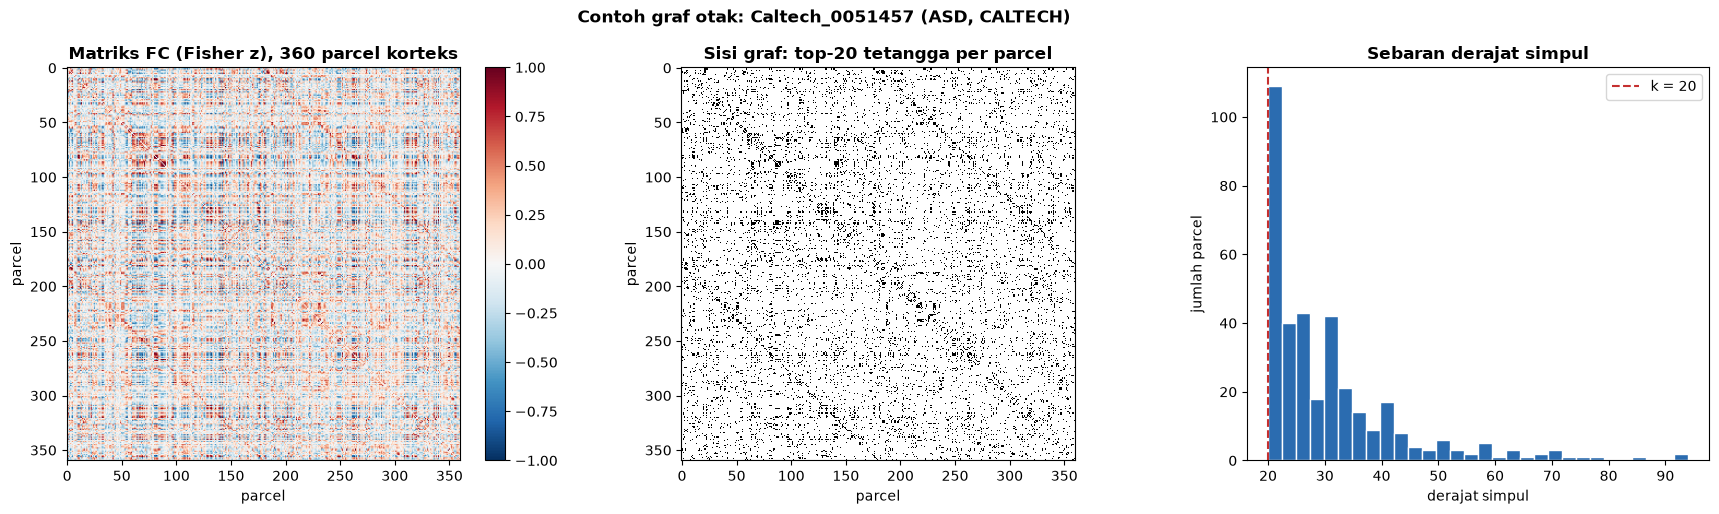

In [4]:
from src.usulan import _matriks
contoh = 0
M = _matriks(np.asarray(KORELASI[contoh:contoh + 1]), ATLAS[ATLAS_GRAF])[0, :N_SIMPUL, :N_SIMPUL]
A = np.zeros((N_SIMPUL, N_SIMPUL))
ei = SISI[contoh][0].numpy()
A[ei[0], ei[1]] = SISI[contoh][1].numpy().ravel()

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), gridspec_kw={"width_ratios": [1, 1, 0.9]})
im = axes[0].imshow(M, cmap="RdBu_r", vmin=-1, vmax=1)
axes[0].set_title("Matriks FC (Fisher z), 360 parcel korteks", fontweight="bold")
plt.colorbar(im, ax=axes[0], fraction=0.046)
axes[1].imshow(A != 0, cmap="Greys", interpolation="nearest")
axes[1].set_title(f"Sisi graf: top-{K_SISI} tetangga per parcel", fontweight="bold")
axes[2].hist(np.bincount(ei[0], minlength=N_SIMPUL), bins=30, color="#2B6CB0", edgecolor="white")
axes[2].axvline(K_SISI, color="#C53030", ls="--", label=f"k = {K_SISI}")
axes[2].set_xlabel("derajat simpul"); axes[2].set_ylabel("jumlah parcel"); axes[2].legend()
axes[2].set_title("Sebaran derajat simpul", fontweight="bold")
for ax in axes[:2]:
    ax.set_xlabel("parcel"); ax.set_ylabel("parcel")
fig.suptitle(f"Contoh graf otak: {kohort.loc[contoh, 'FILE_ID']} ({'ASD' if y[contoh] else 'Kontrol'}, {kohort.loc[contoh, 'situs']})", fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "27_1_contoh_graf_otak.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Fitur sMRI dan Fitur Fenotipik

### 4.1 Morfometri per parcel (sama dengan S2)

Pengolahan sama persis dengan notebook 17: luas dan volume menjadi proporsi terhadap total subjek, ketebalan, kelengkungan, dan sulkus apa adanya, lalu distandardisasi per (parcel, fitur) dengan statistik data latih. Analisis deskriptif morfometri ada di notebook 17 bagian 4; langkah ekstraksinya dijelaskan di notebook 13.

In [5]:
def morfo_relatif(M):
    """(N, R, 5): luas & volume -> proporsi terhadap total subjek; ketebalan, kelengkungan, sulkus apa adanya."""
    M = M.astype(np.float64).copy()
    M[:, :, 0] /= M[:, :, 0].sum(1, keepdims=True)
    M[:, :, 1] /= M[:, :, 1].sum(1, keepdims=True)
    return M.astype(np.float32)

def standar_latih(X, idx_latih):
    """Standardisasi per (parcel, fitur) / per kolom dengan statistik data latih."""
    mu = X[idx_latih].mean(0, keepdims=True)
    sd = X[idx_latih].std(0, keepdims=True) + 1e-6
    return ((X - mu) / sd).astype(np.float32)

assert list(F_SMRI["sub"]) == list(kohort["sub"]), "urutan subjek sMRI tidak sama dengan kohort"
MORFO = morfo_relatif(F_SMRI["morfo_hcp2016"])               # (N, 360, 5)
assert MORFO.shape == (len(kohort), N_SIMPUL, 5) and np.isfinite(MORFO).all()
print("Morfometri:", MORFO.shape)

Morfometri: (1638, 360, 5)


### 4.2 Fitur fenotipik

| Fitur | Isi | Pengolahan (di dalam fold) |
| :--- | :--- | :--- |
| Usia | tahun saat pemindaian | log(usia), karena rentangnya lebar (±5–64 tahun) dan perubahan otak paling cepat di usia muda; lalu standardisasi |
| Jenis kelamin | 0 = laki-laki, 1 = perempuan | apa adanya |
| FIQ | IQ skala penuh | nilai kosong diisi **median data latih**, lalu standardisasi |
| FIQ kosong | 1 bila FIQ tidak tersedia | indikator, supaya model tahu nilai FIQ subjek itu hasil isian |

Situs **tidak** dimasukkan sebagai fitur. Situs bukan ciri biologis subjek, dan memakainya bisa membuat model belajar "situs mana yang punya banyak ASD" alih-alih ciri ASD.

Cabang fenotipik adalah MLP kecil (4 → 64), yang hasilnya masuk ke fusi atensi bersama cabang graf dan cabang linear.

,Kelompok,Subjek,Usia (rata-rata ± SD),Perempuan (%),FIQ (rata-rata ± SD),FIQ kosong
0,Kontrol,924,16.0 ± 8.3,26.200000,112.7 ± 12.6,76
1,ASD,714,16.3 ± 8.6,13.600000,105.5 ± 16.9,53


Uji beda FIQ ASD vs Kontrol: t = -9.47; FIQ kosong per situs: {'ABIDEII-EMC_1': 32, 'ABIDEII-IP_1': 30, 'LEUVEN_2': 29, 'SBL': 19, 'ABIDEII-USM_1': 5, 'UM_1': 4, 'MAX_MUN': 2, 'OLIN': 2, 'CALTECH': 1, 'OHSU': 1, 'ABIDEII-GU_1': 1, 'ABIDEII-KKI_1': 1, 'ABIDEII-NYU_1': 1, 'ABIDEII-UCLA_1': 1}


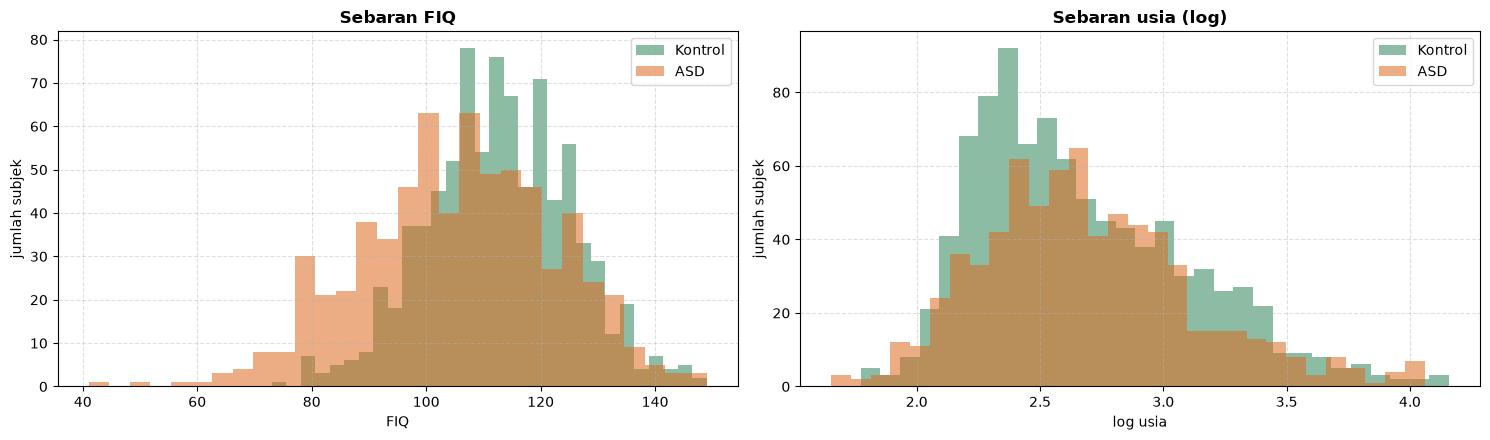

In [6]:
FIQ_KOSONG = kohort["fiq"].isna().to_numpy()
FEN_MENTAH = np.column_stack([np.log(kohort["usia"].to_numpy(float)), (kohort["jenis_kelamin"] == 2).to_numpy(float),
                              kohort["fiq"].to_numpy(float), FIQ_KOSONG.astype(float)])
NAMA_FEN = ["log usia", "perempuan", "FIQ", "FIQ kosong"]

def fitur_fenotipik(idx_latih):
    """(N, 4): FIQ kosong diisi median data latih; log usia dan FIQ distandardisasi dengan statistik data latih."""
    X = FEN_MENTAH.copy()
    X[FIQ_KOSONG, 2] = np.nanmedian(X[idx_latih, 2])
    for j in (0, 2):
        X[:, j] = (X[:, j] - X[idx_latih, j].mean()) / (X[idx_latih, j].std() + 1e-6)
    return X.astype(np.float32)

desk = pd.DataFrame({
    "Kelompok": ["Kontrol", "ASD"],
    "Subjek": [int((y == 0).sum()), int((y == 1).sum())],
    "Usia (rata-rata ± SD)": [f"{kohort['usia'][y == l].mean():.1f} ± {kohort['usia'][y == l].std():.1f}" for l in (0, 1)],
    "Perempuan (%)": [(kohort["jenis_kelamin"][y == l] == 2).mean() * 100 for l in (0, 1)],
    "FIQ (rata-rata ± SD)": [f"{kohort['fiq'][y == l].mean():.1f} ± {kohort['fiq'][y == l].std():.1f}" for l in (0, 1)],
    "FIQ kosong": [int(FIQ_KOSONG[y == l].sum()) for l in (0, 1)],
})
display(desk.round(1).style.set_caption("Fenotipik per kelompok (deskriptif)"))
print(f"Uji beda FIQ ASD vs Kontrol: t = {stats.ttest_ind(kohort['fiq'][y == 1].dropna(), kohort['fiq'][y == 0].dropna()).statistic:.2f}; "
      f"FIQ kosong per situs: {kohort.loc[FIQ_KOSONG, 'situs'].value_counts().to_dict()}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for lab, w, nama in [(0, "#2F855A", "Kontrol"), (1, "#DD6B20", "ASD")]:
    axes[0].hist(kohort["fiq"][y == lab].dropna(), bins=30, alpha=0.55, color=w, label=nama)
    axes[1].hist(np.log(kohort["usia"][y == lab]), bins=30, alpha=0.55, color=w, label=nama)
axes[0].set_xlabel("FIQ"); axes[0].set_title("Sebaran FIQ", fontweight="bold")
axes[1].set_xlabel("log usia"); axes[1].set_title("Sebaran usia (log)", fontweight="bold")
for ax in axes:
    ax.set_ylabel("jumlah subjek"); ax.legend(); ax.grid(alpha=0.4, ls="--")
plt.tight_layout()
fig.savefig(FIG_DIR / "27_2_fenotipik.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Fitur Simpul dan Fitur Cabang Linear (per Fold)

Fitur FC bergantung pada fold karena dihitung dari **FC tangent**, yang acuannya adalah rata-rata geometrik kovarians **subjek latih** fold tersebut (berkas `tangent_<atlas>_gab_<k>.npy` dari notebook 10; langkahnya dijelaskan di notebook 11). Morfometri tidak bergantung fold, tetapi standardisasinya memakai statistik data latih fold tersebut.

| Fitur | Bentuk per subjek | Pengolahan (statistik dari data latih fold) |
| :--- | :--- | :--- |
| Fitur simpul cabang graf | 360 × **384** = 379 baris tangent HCP + 5 morfometri | standardisasi per (parcel, fitur), FC dan morfometri masing-masing |
| Fitur cabang linear | ±3.900 skor PCA (3 atlas) | standardisasi per fitur → proyeksi ke seluruh komponen utama data latih |

Fungsi `siapkan_fold` dipanggil sekali per fold. Hasil fold terakhir disimpan di memori, sehingga pemeriksaan di bawah (fold 0) langsung dipakai ulang saat pelatihan.

In [7]:
_simpan = {}

def siapkan_fold(k, idx_latih_penuh):
    """Data PyG untuk SEMUA subjek pada fold k; statistik fitur hanya dari idx_latih_penuh."""
    if _simpan.get("fold") == k:
        return _simpan["data"]
    _simpan.clear()
    gc.collect()                       # lepaskan fitur fold sebelumnya (±1 GB) sebelum membuat yang baru
    V = {a: np.load(FITUR_22 / f"tangent_{a}_gab_{k}.npy", mmap_mode="r") for a in ATLAS}
    X_fc = fitur_simpul_baris(V[ATLAS_GRAF], ATLAS[ATLAS_GRAF], N_SIMPUL, idx_latih_penuh)              # (N, 360, 379)
    X_simpul = np.concatenate([X_fc, standar_latih(MORFO, idx_latih_penuh)], axis=2)                    # (N, 360, 384)
    del X_fc
    X_linear = fitur_linear_pca([V[a] for a in ATLAS], idx_latih_penuh)
    data = buat_graf(y, X_simpul, SISI, X_linear=X_linear, X_fenotipe=fitur_fenotipik(idx_latih_penuh))
    _simpan.update(fold=k, data=data, X_simpul=X_simpul, X_linear=X_linear)
    return data

t0 = time.perf_counter()
latih0 = np.where(fold != 0)[0]
data0 = siapkan_fold(0, latih0)
Xs, Xl = _simpan["X_simpul"], _simpan["X_linear"]
display(pd.DataFrame({
    "Fitur": ["simpul (cabang graf)", "linear (cabang linear)"],
    "Bentuk": [f"{Xs.shape[0]} × {Xs.shape[1]} × {Xs.shape[2]}", f"{Xl.shape[0]} × {Xl.shape[1]}"],
    "Rata-rata data latih": [float(Xs[latih0].mean()), float(Xl[latih0].mean())],
    "SD data latih": [float(Xs[latih0].std()), float(Xl[latih0].std())],
    "Nilai tidak finit": [int((~np.isfinite(Xs)).sum()), int((~np.isfinite(Xl)).sum())],
}).round(4).style.set_caption(f"Fitur fold 0 ({time.perf_counter() - t0:.0f} detik)"))
display(pd.DataFrame({"Bagian fitur simpul": ["FC tangent (kolom 0–378)", "morfometri (kolom 379–383)"],
                      "Rata-rata data latih": [float(Xs[latih0][:, :, :379].mean()), float(Xs[latih0][:, :, 379:].mean())],
                      "SD data latih": [float(Xs[latih0][:, :, :379].std()), float(Xs[latih0][:, :, 379:].std())]}).round(4))
display(pd.DataFrame(data0[0].x_fen.numpy(), columns=NAMA_FEN).round(3).style.set_caption("Contoh fitur fenotipik subjek pertama (sudah diolah)"))
print("Contoh satu objek graf:", data0[0])

,Fitur,Bentuk,Rata-rata data latih,SD data latih,Nilai tidak finit
0,simpul (cabang graf),1638 × 360 × 384,0.000000,0.998700,0
1,linear (cabang linear),1638 × 3927,-0.000000,0.027600,0


,Bagian fitur simpul,Rata-rata data latih,SD data latih
0,FC tangent (kolom 0–378),0.0,0.9987
1,morfometri (kolom 379–383),0.0,0.9985


,log usia,perempuan,FIQ,FIQ kosong
0,1.052000,0.000000,-0.192000,0.000000


Contoh satu objek graf: Data(x=[360, 384], edge_index=[2, 11108], edge_attr=[11108, 1], y=[1], x_lin=[1, 3927], x_fen=[1, 4])


## 6. Model dan Pemeriksaan Bentuk Tensor

Sebelum pelatihan, satu batch kecil dilewatkan ke model untuk memastikan bentuk tensor setiap tahap sudah benar.

In [8]:
def buat_model(contoh):
    return ModelUsulan(N_SIMPUL, d_simpul=contoh.x.size(1), d_linear=contoh.x_lin.size(1), d_fenotipe=contoh.x_fen.size(1), **HIPER_MODEL)

from torch_geometric.loader import DataLoader
model_cek = buat_model(data0[0]).to(DEVICE).eval()
b = next(iter(DataLoader(data0[:4], batch_size=4))).to(DEVICE)
with torch.no_grad():
    logit = model_cek(b)
display(pd.DataFrame([
    {"Tahap": "input fitur simpul (4 graf digabung)", "Bentuk": tuple(b.x.shape)},
    {"Tahap": "input sisi (edge_index)", "Bentuk": tuple(b.edge_index.shape)},
    {"Tahap": "input cabang linear", "Bentuk": tuple(b.x_lin.shape)},
    {"Tahap": "input cabang fenotipik", "Bentuk": tuple(b.x_fen.shape)},
    {"Tahap": "bobot atensi parcel α (per subjek)", "Bentuk": tuple(model_cek.alpha().shape)},
    {"Tahap": "bobot cabang β (graf, linear, fenotipik)", "Bentuk": tuple(model_cek.beta_terakhir.shape)},
    {"Tahap": "keluaran logits [Kontrol, ASD]", "Bentuk": tuple(logit.shape)},
]))
param = {n: sum(p.numel() for p in model_cek.cabang[n].parameters()) for n in model_cek.nama_cabang}
param["fusi + kepala"] = sum(p.numel() for p in model_cek.parameters()) - sum(param.values())
display(pd.DataFrame({"Bagian": list(param), "Jumlah parameter": list(param.values())}).style.set_caption(
    f"Total parameter: {sum(param.values()):,}"))
assert torch.allclose(model_cek.alpha().sum(1), torch.ones(4, device=DEVICE)), "α setiap subjek harus berjumlah 1"
del model_cek, b, data0, Xs, Xl      # nama-nama ini menahan fitur fold 0 (±1 GB) di memori; lepaskan sebelum pelatihan
gc.collect()

,Tahap,Bentuk
0,input fitur simpul (4 graf digabung),"(1440, 384)"
1,input sisi (edge_index),"(2, 42624)"
2,input cabang linear,"(4, 3927)"
3,input cabang fenotipik,"(4, 4)"
4,bobot atensi parcel α (per subjek),"(4, 360)"
5,"bobot cabang β (graf, linear, fenotipik)","(4, 3)"
6,"keluaran logits [Kontrol, ASD]","(4, 2)"


,Bagian,Jumlah parameter
0,graf,167813
1,linear,251392
2,fenotipik,4480
3,fusi + kepala,7177


108

## 7. Pelatihan 5-Fold

| Hyperparameter | Nilai |
| :--- | :--- |
| Dimensi tersembunyi, lapis GATv2, head | 64, 2, 4 |
| Dropout (umum / input simpul / sisi / input linear) | 0,5 / 0,2 / 0,2 / 0,2 |
| Optimizer | AdamW, lr 10⁻³, weight decay 10⁻³, cosine annealing |
| Batch, epoch maksimum, *patience* | 32, 200, 40 (minimal 20 epoch) |
| Loss | cross-entropy berbobot kelas + 0,5 × rata-rata loss kepala bantu |
| Pengulangan | 5 run (seed 0–4) |

Sel berikut adalah bagian terlama. Setiap baris log menunjukkan satu seed selesai, dan setiap fold yang selesai langsung disimpan.

In [9]:
t0 = time.perf_counter()
HASIL = jalankan_cv_usulan(y, situs, fold, siapkan_fold, buat_model, cfg=CFG_LATIH, cache_dir=CACHE_DIR)
_simpan.clear()
print(f"\nSelesai dalam {(time.perf_counter() - t0) / 60:.1f} menit (≈0 berarti semua fold dibaca dari cache).")

    fold 0 seed 0: epoch terbaik  20 | AUC val 68.93 | 2.7 menit
    fold 0 seed 1: epoch terbaik  44 | AUC val 74.12 | 3.8 menit
    fold 0 seed 2: epoch terbaik  50 | AUC val 78.89 | 4.2 menit
    fold 0 seed 3: epoch terbaik  29 | AUC val 71.82 | 3.3 menit
    fold 0 seed 4: epoch terbaik  24 | AUC val 77.44 | 3.1 menit
  fold 0: ACC 74.09 | AUC 82.00 (17 menit berjalan)
    fold 1 seed 0: epoch terbaik 106 | AUC val 73.59 | 7.1 menit
    fold 1 seed 1: epoch terbaik  30 | AUC val 75.06 | 3.4 menit
    fold 1 seed 2: epoch terbaik  28 | AUC val 73.80 | 3.3 menit
    fold 1 seed 3: epoch terbaik  60 | AUC val 75.10 | 4.9 menit
    fold 1 seed 4: epoch terbaik  33 | AUC val 72.16 | 3.5 menit
  fold 1: ACC 69.97 | AUC 78.05 (40 menit berjalan)
    fold 2 seed 0: epoch terbaik  64 | AUC val 81.43 | 5.0 menit
    fold 2 seed 1: epoch terbaik  89 | AUC val 76.23 | 6.3 menit
    fold 2 seed 2: epoch terbaik  29 | AUC val 76.31 | 3.4 menit
    fold 2 seed 3: epoch terbaik  31 | AUC val 75.6

## 8. Hasil

### 8.1 Hasil 5 run

Setiap baris adalah satu validasi silang 5-fold lengkap dengan seed berbeda. Metrik setiap run = rata-rata 5 fold. Baris terakhir adalah **hasil utama S3**: rata-rata ± SD antar run.

In [10]:
P_LR = np.mean([np.load(CACHE_22 / f"C3_gab_tangent_{a}.npz")["p"] for a in ATLAS], axis=0)
N_RUN = HASIL["p_run"].shape[1]
KOLOM = {"accuracy": "Akurasi", "balanced": "Balanced acc.", "sensitivity": "Sensitivitas", "specificity": "Spesifisitas",
         "precision": "Presisi", "f1": "F1", "auc": "AUC"}

def metrik_per_fold(p):
    df = pd.DataFrame([{"fold": k, **hitung_metrik(y[fold == k], p[fold == k])} for k in sorted(np.unique(fold))])
    df["balanced"] = (df["sensitivity"] + df["specificity"]) / 2
    return df

def rata_fold(p):
    return metrik_per_fold(p)[list(KOLOM)].mean() * 100

tab_run = pd.DataFrame([rata_fold(HASIL["p_run"][:, r]) for r in range(N_RUN)], index=[f"run {r + 1} (seed {r})" for r in range(N_RUN)])
tab_run.columns = [f"{KOLOM[k]} (%)" for k in tab_run.columns]
tab_run_tampil = tab_run.round(2).astype(str)
tab_run_tampil.loc["Rata-rata ± SD antar run"] = [f"{m:.2f} ± {s:.2f}" for m, s in zip(tab_run.mean(), tab_run.std(ddof=1))]
display(tab_run_tampil.style.set_caption(f"S3: {N_RUN} run × 5-fold (1.638 subjek)"))
tab_run_tampil.to_csv(TABEL_DIR / "27_S3_per_run.csv")

,Akurasi (%),Balanced acc. (%),Sensitivitas (%),Spesifisitas (%),Presisi (%),F1 (%),AUC (%)
run 1 (seed 0),71.96,70.02,55.58,84.46,73.97,63.16,79.63
run 2 (seed 1),70.86,69.49,58.14,80.85,70.65,63.09,78.97
run 3 (seed 2),71.73,70.77,62.49,79.06,70.15,65.56,78.97
run 4 (seed 3),72.94,71.83,63.25,80.42,72.05,67.09,80.05
run 5 (seed 4),71.44,70.3,60.35,80.25,70.8,64.29,79.41
Rata-rata ± SD antar run,71.78 ± 0.76,70.48 ± 0.89,59.96 ± 3.16,81.01 ± 2.04,71.52 ± 1.54,64.64 ± 1.70,79.40 ± 0.46


### 8.2 Perbandingan dengan baseline

| Baris | Arti | SD |
| :--- | :--- | :--- |
| **S3 model usulan (5 run)** | hasil utama | antar run |
| S3 ensemble 5 run | probabilitas kelima run dirata-rata | antar fold |
| kepala bantu: cabang graf / linear / fenotipik | prediksi kepala bantu satu cabang pada model yang sama (ensemble 5 run). **Bukan** model terpisah. Notebook ablasi tidak dibuat; sumbangan setiap komponen dibaca dari perbandingan berpasangan S1 → S3 | antar fold |
| Baseline LR (notebook 10) | FC tangent 3 atlas, subjek dan fold sama. Penjelasan lengkap di notebook 14; label di tabel dan grafik tetap "notebook 22" (nomor lama notebook 10) karena probabilitasnya dibuat di sana | antar fold |

In [11]:
PRED = {"S3 ensemble 5 run": HASIL["p"], "  kepala bantu: cabang graf": HASIL["p_graf"],
        "  kepala bantu: cabang linear": HASIL["p_linear"], "  kepala bantu: cabang fenotipik": HASIL["p_fenotipik"],
        "Baseline LR (notebook 22)": P_LR}

def ringkas_fold(p):
    df = metrik_per_fold(p)
    return {f"{v} (%)": f"{df[k].mean() * 100:.2f} ± {df[k].std(ddof=0) * 100:.2f}" for k, v in KOLOM.items()}

tab_hasil = pd.DataFrame({"S3 model usulan (5 run)": tab_run_tampil.loc["Rata-rata ± SD antar run"].to_dict(),
                          **{n: ringkas_fold(p) for n, p in PRED.items()}}).T
display(tab_hasil.style.set_caption("S3 vs baseline"))

per_fold = metrik_per_fold(HASIL["p"]).set_index("fold")[list(KOLOM)] * 100
per_fold["LR akurasi"] = metrik_per_fold(P_LR).set_index("fold")["accuracy"] * 100
display(per_fold.round(2).style.set_caption("S3 ensemble per fold (%)"))

tab_hasil.to_csv(TABEL_DIR / "27_S3_ringkasan.csv")
per_fold.to_csv(TABEL_DIR / "27_S3_per_fold.csv")
pd.DataFrame({"FILE_ID": kohort["FILE_ID"], "dataset": dataset, "situs": situs, "fold": fold, "y_true": y,
              "p_ensemble": HASIL["p"], **{f"p_run{r + 1}": HASIL["p_run"][:, r] for r in range(N_RUN)},
              "p_graf": HASIL["p_graf"], "p_linear": HASIL["p_linear"], "p_fenotipik": HASIL["p_fenotipik"], "p_lr": P_LR}).to_csv(TABEL_DIR / "27_S3_prediksi.csv", index=False)
with open(METRIK_DIR / "S3_ringkasan.json", "w", encoding="utf-8") as f:
    json.dump({"skenario": SKENARIO, "notebook": "27", "n_subjek": int(len(y)), "n_run": int(N_RUN),
               "rata_rata_antar_run": tab_run.mean().round(4).to_dict(), "sd_antar_run": tab_run.std(ddof=1).round(4).to_dict(),
               "per_run": tab_run.round(4).to_dict(orient="index"), "ensemble": rata_fold(HASIL["p"]).round(4).to_dict(),
               "hiper_model": HIPER_MODEL, "cfg_latih": {k: list(v) if isinstance(v, tuple) else v for k, v in CFG_LATIH.items()},
               "k_sisi": K_SISI, "fusi": "penjumlahan logit (Wide & Deep)"}, f, indent=2)

,Akurasi (%),Balanced acc. (%),Sensitivitas (%),Spesifisitas (%),Presisi (%),F1 (%),AUC (%)
S3 model usulan (5 run),71.78 ± 0.76,70.48 ± 0.89,59.96 ± 3.16,81.01 ± 2.04,71.52 ± 1.54,64.64 ± 1.70,79.40 ± 0.46
S3 ensemble 5 run,73.37 ± 1.85,72.04 ± 1.89,61.25 ± 6.08,82.83 ± 4.49,73.72 ± 3.84,66.60 ± 2.90,81.23 ± 1.74
kepala bantu: cabang graf,68.92 ± 1.26,68.24 ± 1.31,62.74 ± 5.89,73.74 ± 4.85,65.11 ± 2.67,63.65 ± 2.21,73.68 ± 1.60
kepala bantu: cabang linear,73.19 ± 2.34,71.66 ± 2.14,59.80 ± 2.56,83.53 ± 3.50,73.94 ± 4.26,66.05 ± 2.45,80.88 ± 1.74
kepala bantu: cabang fenotipik,62.34 ± 0.96,60.32 ± 1.24,43.99 ± 5.84,76.65 ± 3.70,59.35 ± 1.76,50.22 ± 3.55,65.98 ± 2.24
Baseline LR (notebook 22),73.23 ± 3.48,71.83 ± 3.48,61.14 ± 5.65,82.52 ± 3.84,73.18 ± 4.59,66.50 ± 4.52,81.35 ± 2.14


,accuracy,balanced,sensitivity,specificity,precision,f1,auc,LR akurasi
fold,,,,,,,,
0,74.090000,72.650000,59.590000,85.710000,76.990000,67.180000,82.000000,72.260000
1,69.970000,68.290000,52.780000,83.800000,72.380000,61.040000,78.050000,67.180000
2,74.330000,73.270000,64.190000,82.350000,74.220000,68.840000,82.390000,77.310000
3,73.090000,72.810000,71.010000,74.600000,67.120000,69.010000,80.800000,73.700000
4,75.380000,73.200000,58.700000,87.700000,77.880000,66.940000,82.930000,75.690000


### 8.3 Uji kebermaknaan terhadap baseline

Uji McNemar membandingkan prediksi benar/salah **per subjek** antara dua model pada subjek uji yang sama. Setiap run diuji terhadap LR, ditambah ensemble dan kepala bantu setiap cabang. Karena ada beberapa perbandingan, nilai p dikoreksi dengan metode Holm.

In [12]:
def mcnemar(pa, pb):
    A, B = (pa >= 0.5).astype(int) == y, (pb >= 0.5).astype(int) == y
    n01, n10 = int((~A & B).sum()), int((A & ~B).sum())
    return {"Selisih akurasi (poin)": round((B.mean() - A.mean()) * 100, 2), "Hanya benar di model": n01, "Hanya benar di LR": n10,
            "p": stats.binomtest(n01, n01 + n10, 0.5).pvalue if n01 + n10 else 1.0}

UJI = {**{f"S3 run {r + 1}": HASIL["p_run"][:, r] for r in range(N_RUN)}, **{n: p for n, p in PRED.items() if not n.startswith("Baseline")}}
uji = pd.DataFrame([{"Model (dibanding baseline LR)": n.strip(), **mcnemar(P_LR, p)} for n, p in UJI.items()])
urut = np.argsort(uji["p"].to_numpy())
holm = np.minimum(1, np.maximum.accumulate(uji["p"].to_numpy()[urut] * (len(uji) - np.arange(len(uji)))))
uji.loc[uji.index[urut], "p Holm"] = holm
uji["Kesimpulan"] = np.where(uji["p Holm"] >= 0.05, "setara (tidak berbeda bermakna)",
                             np.where(uji["Selisih akurasi (poin)"] > 0, "lebih baik secara bermakna", "lebih rendah secara bermakna"))
display(uji.round(4).style.set_caption("Uji McNemar + koreksi Holm"))
uji.to_csv(TABEL_DIR / "27_S3_uji_mcnemar.csv", index=False)

,Model (dibanding baseline LR),Selisih akurasi (poin),Hanya benar di model,Hanya benar di LR,p,p Holm,Kesimpulan
0,S3 run 1,-1.280000,107,128,0.191900,0.767600,setara (tidak berbeda bermakna)
1,S3 run 2,-2.380000,119,158,0.022200,0.155700,setara (tidak berbeda bermakna)
2,S3 run 3,-1.530000,106,131,0.118800,0.594100,setara (tidak berbeda bermakna)
3,S3 run 4,-0.310000,110,115,0.789800,1.000000,setara (tidak berbeda bermakna)
4,S3 run 5,-1.830000,126,156,0.084000,0.504000,setara (tidak berbeda bermakna)
5,S3 ensemble 5 run,0.120000,85,83,0.938500,1.000000,setara (tidak berbeda bermakna)
6,kepala bantu: cabang graf,-4.330000,156,227,0.000300,0.002700,lebih rendah secara bermakna
7,kepala bantu: cabang linear,-0.060000,48,49,1.000000,1.000000,setara (tidak berbeda bermakna)
8,kepala bantu: cabang fenotipik,-10.930000,229,408,0.000000,0.000000,lebih rendah secara bermakna


### 8.4 Perbandingan dengan S2: apakah fenotipik menambah informasi?

Ini pertanyaan utama S3. S2 dan S3 memakai fold dan seed yang sama, jadi **run ke-r di S3 dibandingkan dengan run ke-r di S2** (berpasangan):
- selisih akurasi per run, beserta rata-ratanya;
- uji t berpasangan antar 5 run (apakah selisihnya konsisten, bukan kebetulan seed);
- uji McNemar per subjek antara ensemble S3 dan ensemble S2.

In [13]:
S2 = pd.read_csv(TABEL_DIR / "26_S2_prediksi.csv")
assert (S2["FILE_ID"].to_numpy() == kohort["FILE_ID"].to_numpy()).all(), "urutan subjek S2 dan S3 berbeda"
P1_RUN = S2[[f"p_run{r + 1}" for r in range(N_RUN)]].to_numpy()
banding = pd.DataFrame({"run": [f"run {r + 1}" for r in range(N_RUN)],
                        "Akurasi S2 (%)": [rata_fold(P1_RUN[:, r])["accuracy"] for r in range(N_RUN)],
                        "Akurasi S3 (%)": [rata_fold(HASIL["p_run"][:, r])["accuracy"] for r in range(N_RUN)],
                        "AUC S2 (%)": [rata_fold(P1_RUN[:, r])["auc"] for r in range(N_RUN)],
                        "AUC S3 (%)": [rata_fold(HASIL["p_run"][:, r])["auc"] for r in range(N_RUN)]})
banding["Selisih akurasi (S3 − S2)"] = banding["Akurasi S3 (%)"] - banding["Akurasi S2 (%)"]
banding["Selisih AUC (S3 − S2)"] = banding["AUC S3 (%)"] - banding["AUC S2 (%)"]
t_acc = stats.ttest_rel(banding["Akurasi S3 (%)"], banding["Akurasi S2 (%)"])
t_auc = stats.ttest_rel(banding["AUC S3 (%)"], banding["AUC S2 (%)"])
display(banding.round(2).style.set_caption(
    f"S3 vs S2 per run | rata-rata selisih akurasi {banding['Selisih akurasi (S3 − S2)'].mean():+.2f} poin (uji t berpasangan p = {t_acc.pvalue:.3f}), "
    f"AUC {banding['Selisih AUC (S3 − S2)'].mean():+.2f} poin (p = {t_auc.pvalue:.3f})"))

uji_s1 = pd.DataFrame([{"Perbandingan": "ensemble S2 → ensemble S3", **mcnemar(S2["p_ensemble"].to_numpy(), HASIL["p"])},
                       {"Perbandingan": "kepala bantu graf S2 → S3", **mcnemar(S2["p_graf"].to_numpy(), HASIL["p_graf"])}])
uji_s1 = uji_s1.rename(columns={"Hanya benar di model": "Hanya benar di S3", "Hanya benar di LR": "Hanya benar di S2"})
uji_s1["Bermakna (p < 0,05)"] = np.where(uji_s1["p"] < 0.05, "ya", "tidak")
display(uji_s1.round(4).style.set_caption("Uji McNemar S2 vs S3 (subjek sama)"))
banding.to_csv(TABEL_DIR / "27_S3_vs_S2_per_run.csv", index=False)
uji_s1.to_csv(TABEL_DIR / "27_S3_vs_S2_mcnemar.csv", index=False)

,run,Akurasi S2 (%),Akurasi S3 (%),AUC S2 (%),AUC S3 (%),Selisih akurasi (S3 − S2),Selisih AUC (S3 − S2)
0,run 1,70.320000,71.960000,78.030000,79.630000,1.640000,1.600000
1,run 2,69.760000,70.860000,78.340000,78.970000,1.100000,0.630000
2,run 3,71.250000,71.730000,77.270000,78.970000,0.480000,1.700000
3,run 4,72.140000,72.940000,77.830000,80.050000,0.790000,2.220000
4,run 5,71.300000,71.440000,77.410000,79.410000,0.140000,2.000000


,Perbandingan,Selisih akurasi (poin),Hanya benar di S3,Hanya benar di S2,p,"Bermakna (p < 0,05)"
0,ensemble S2 → ensemble S3,0.310000,86,81,0.757000,tidak
1,kepala bantu graf S2 → S3,1.160000,166,147,0.308900,tidak


### 8.5 Grafik ringkasan

- **Kiri**: akurasi, balanced accuracy, dan AUC. Batang S3 = rata-rata 5 run (titik = setiap run); batang lain = ensemble/baseline (titik = setiap fold);
- **Tengah**: kurva ROC seluruh subjek uji;
- **Kanan**: confusion matrix S3 ensemble (ambang 0,5).

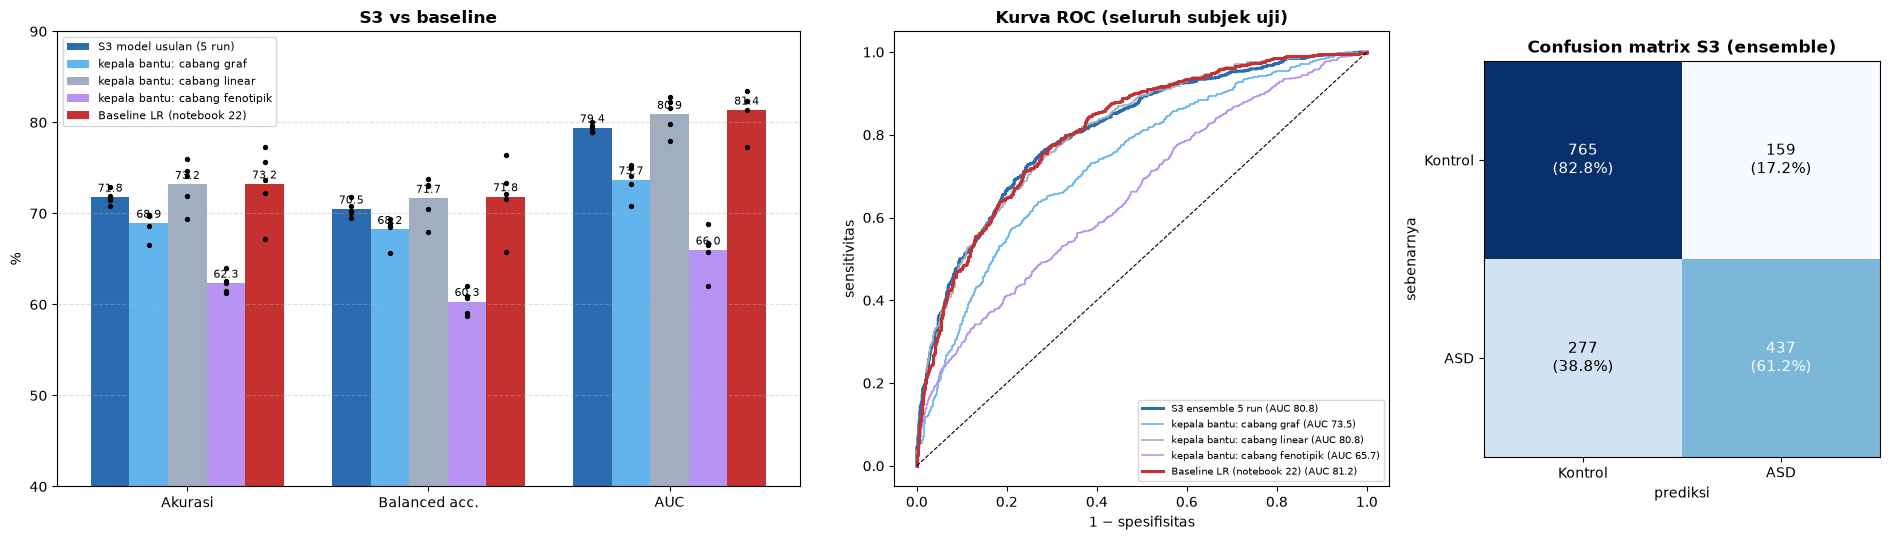

In [14]:
WARNA = {"S3 model usulan (5 run)": "#2B6CB0", "  kepala bantu: cabang graf": "#63B3ED", "  kepala bantu: cabang linear": "#A0AEC0", "  kepala bantu: cabang fenotipik": "#B794F4",
         "Baseline LR (notebook 22)": "#C53030"}
metrik_plot = [("accuracy", "Akurasi"), ("balanced", "Balanced acc."), ("auc", "AUC")]
titik = {"S3 model usulan (5 run)": [[rata_fold(HASIL["p_run"][:, r])[m] for r in range(N_RUN)] for m, _ in metrik_plot]}
for n in ("  kepala bantu: cabang graf", "  kepala bantu: cabang linear", "  kepala bantu: cabang fenotipik", "Baseline LR (notebook 22)"):
    df = metrik_per_fold(PRED[n])
    titik[n] = [list(df[m] * 100) for m, _ in metrik_plot]

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), gridspec_kw={"width_ratios": [1.5, 1, 0.8]})
lebar = 0.8 / len(titik)
for j, (n, nilai) in enumerate(titik.items()):
    x = np.arange(len(metrik_plot)) + (j - (len(titik) - 1) / 2) * lebar
    rata = [np.mean(v) for v in nilai]
    axes[0].bar(x, rata, lebar, color=WARNA[n], label=n.strip())
    for xi, v in zip(x, nilai):
        axes[0].scatter(np.full(len(v), xi), v, color="black", s=8, zorder=3)
    for xi, r in zip(x, rata):
        axes[0].text(xi, max(r, 40) + 0.6, f"{r:.1f}", ha="center", fontsize=8)
axes[0].set_xticks(range(len(metrik_plot))); axes[0].set_xticklabels([t for _, t in metrik_plot])
axes[0].set_ylim(40, 90); axes[0].set_ylabel("%"); axes[0].legend(fontsize=8, loc="upper left")
axes[0].set_title("S3 vs baseline", fontweight="bold"); axes[0].grid(axis="y", alpha=0.4, ls="--")

WARNA_ROC = {"S3 ensemble 5 run": "#2B6CB0", **{k: v for k, v in WARNA.items() if k != "S3 model usulan (5 run)"}}
for n, p in PRED.items():
    fpr, tpr, _ = roc_curve(y, p)
    axes[1].plot(fpr, tpr, color=WARNA_ROC[n], lw=2.2 if n.startswith("S3") or n.startswith("Baseline") else 1.2,
                 label=f"{n.strip()} (AUC {hitung_metrik(y, p)['auc'] * 100:.1f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[1].set_xlabel("1 − spesifisitas"); axes[1].set_ylabel("sensitivitas"); axes[1].legend(fontsize=7.5, loc="lower right")
axes[1].set_title("Kurva ROC (seluruh subjek uji)", fontweight="bold")

cm = confusion_matrix(y, (HASIL["p"] >= 0.5).astype(int))
axes[2].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        axes[2].text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum() * 100:.1f}%)", ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=11)
axes[2].set_xticks([0, 1]); axes[2].set_xticklabels(["Kontrol", "ASD"]); axes[2].set_yticks([0, 1]); axes[2].set_yticklabels(["Kontrol", "ASD"])
axes[2].set_xlabel("prediksi"); axes[2].set_ylabel("sebenarnya"); axes[2].set_title("Confusion matrix S3 (ensemble)", fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "27_3_hasil_s3.png", dpi=150, bbox_inches="tight")
plt.show()

### 8.6 Akurasi per dataset dan per situs

Model dilatih pada gabungan ABIDE I + II. Di sini dicek apakah performanya **merata** pada kedua dataset dan seluruh situs, atau hanya bagus di sebagian.

,Subjek,Akurasi S3 ensemble (%),Akurasi LR (%)
ABIDE I,886,73.250000,73.360000
ABIDE II,752,73.540000,73.140000


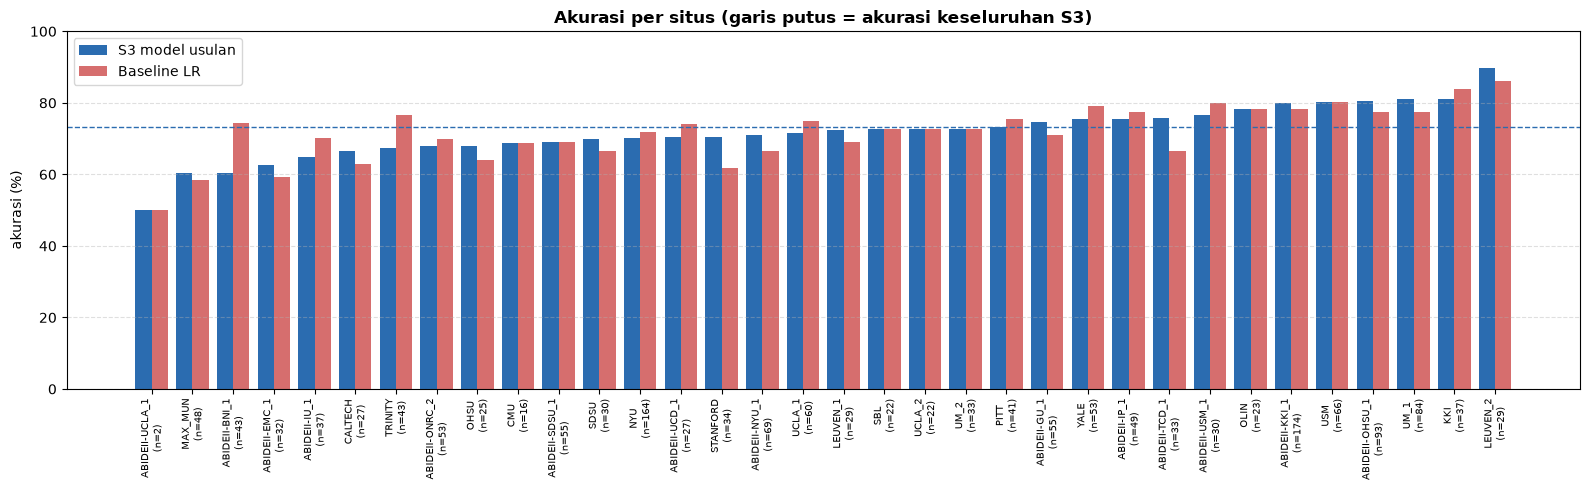

In [15]:
benar = lambda p: ((p >= 0.5).astype(int) == y)
per_ds = pd.DataFrame({"Subjek": pd.Series(dataset).value_counts(),
                       "Akurasi S3 ensemble (%)": pd.Series(benar(HASIL["p"])).groupby(dataset).mean() * 100,
                       "Akurasi LR (%)": pd.Series(benar(P_LR)).groupby(dataset).mean() * 100})
per_ds.index = per_ds.index.map({"abide1": "ABIDE I", "abide2": "ABIDE II"})
display(per_ds.round(2).style.set_caption("Akurasi per dataset"))

per_situs = (pd.DataFrame({"situs": situs, "S3": benar(HASIL["p"]), "LR": benar(P_LR)})
             .groupby("situs").agg(n=("S3", "size"), S3=("S3", "mean"), LR=("LR", "mean")).sort_values("S3"))
per_situs[["S3", "LR"]] *= 100
fig, ax = plt.subplots(figsize=(16, 5))
x = np.arange(len(per_situs))
ax.bar(x - 0.2, per_situs["S3"], 0.4, color="#2B6CB0", label="S3 model usulan")
ax.bar(x + 0.2, per_situs["LR"], 0.4, color="#C53030", alpha=0.7, label="Baseline LR")
ax.axhline(benar(HASIL["p"]).mean() * 100, color="#2B6CB0", ls="--", lw=1)
ax.set_xticks(x); ax.set_xticklabels([f"{s}\n(n={n})" for s, n in zip(per_situs.index, per_situs["n"])], rotation=90, fontsize=7.5)
ax.set_ylabel("akurasi (%)"); ax.set_ylim(0, 100); ax.legend(); ax.grid(axis="y", alpha=0.4, ls="--")
ax.set_title("Akurasi per situs (garis putus = akurasi keseluruhan S3)", fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "27_4_akurasi_per_situs_s3.png", dpi=150, bbox_inches="tight")
plt.show()
per_situs.round(2).to_csv(TABEL_DIR / "27_S3_per_situs.csv")

### 8.7 Kurva belajar

Loss latih dan AUC validasi setiap epoch, untuk 5 fold × 5 run. Kurva ini dipakai untuk mengecek **overfitting**: loss latih terus turun, sementara AUC validasi berhenti naik. Titik merah adalah epoch yang bobotnya dipakai (AUC validasi terbaik).

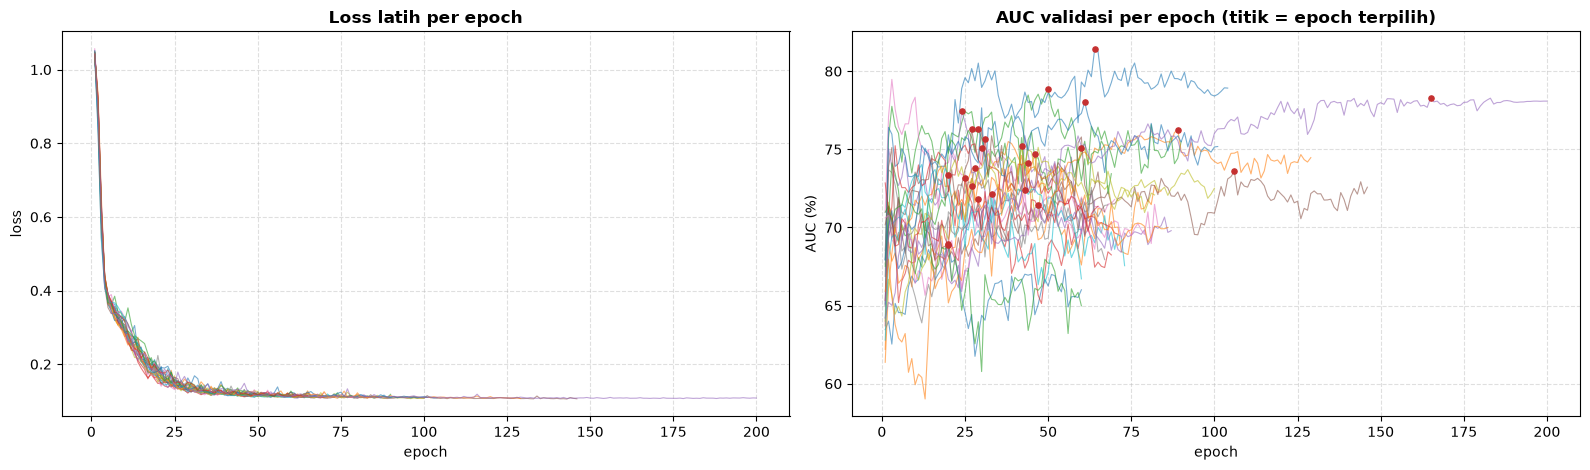

,fold,seed,epoch_terbaik,auc_val,detik
0,0,0,20,0.689000,159.254000
1,0,1,44,0.741000,226.675000
2,0,2,50,0.789000,254.604000
3,0,3,29,0.718000,200.097000
4,0,4,24,0.774000,187.357000
5,1,0,106,0.736000,424.096000
6,1,1,30,0.751000,206.076000
7,1,2,28,0.738000,199.996000
8,1,3,60,0.751000,291.640000
9,1,4,33,0.722000,212.952000


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for l in HASIL["log"]:
    r = l["riwayat"]
    axes[0].plot(r[:, 0], r[:, 1], lw=0.8, alpha=0.6)
    axes[1].plot(r[:, 0], r[:, 2] * 100, lw=0.8, alpha=0.6)
    axes[1].scatter(l["epoch_terbaik"], l["auc_val"] * 100, color="#C53030", s=14, zorder=3)
axes[0].set_title("Loss latih per epoch", fontweight="bold"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss")
axes[1].set_title("AUC validasi per epoch (titik = epoch terpilih)", fontweight="bold"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("AUC (%)")
for ax in axes:
    ax.grid(alpha=0.4, ls="--")
plt.tight_layout()
fig.savefig(FIG_DIR / "27_5_kurva_belajar_s3.png", dpi=150, bbox_inches="tight")
plt.show()
log_df = pd.DataFrame([{k: v for k, v in l.items() if k != "riwayat"} for l in HASIL["log"]])
display(log_df.round(3).style.set_caption("Ringkasan setiap seed"))
log_df.to_csv(TABEL_DIR / "27_S3_log_seed.csv", index=False)

### 8.8 Interpretasi: bobot cabang (β) dan parcel terpenting (α)

- **β**: seberapa besar model mengandalkan cabang graf, cabang linear, dan cabang fenotipik untuk setiap subjek (garis putus = 1/3, bobot rata);
- **α** (*node-attention pooling*): bobot setiap parcel dalam ringkasan graf. Nilai rata-rata 1/360 ≈ 0,0028 berarti "rata-rata". Parcel dengan α tinggi adalah wilayah yang paling diperhatikan model.

Bobot β dan α dihitung pada **subjek uji** setiap fold (rata-rata 5 run), lalu dirata-rata antar subjek.

,Parcel HCP,α rata-rata (×1000),α ASD (×1000),α Kontrol (×1000),Kali dari rata-rata
0,R_43_ROI,3.198000,3.165000,3.223000,1.151000
1,L_STSdp_ROI,3.178000,3.163000,3.189000,1.144000
2,L_8BM_ROI,3.164000,3.162000,3.164000,1.139000
3,L_1_ROI,3.118000,3.030000,3.187000,1.123000
4,R_A5_ROI,3.105000,3.038000,3.157000,1.118000
5,R_OP4_ROI,3.102000,3.056000,3.137000,1.117000
6,R_PBelt_ROI,3.093000,3.022000,3.147000,1.113000
7,L_OP4_ROI,3.070000,3.008000,3.118000,1.105000
8,R_a9-46v_ROI,3.048000,3.081000,3.023000,1.097000
9,L_3b_ROI,3.044000,3.017000,3.065000,1.096000


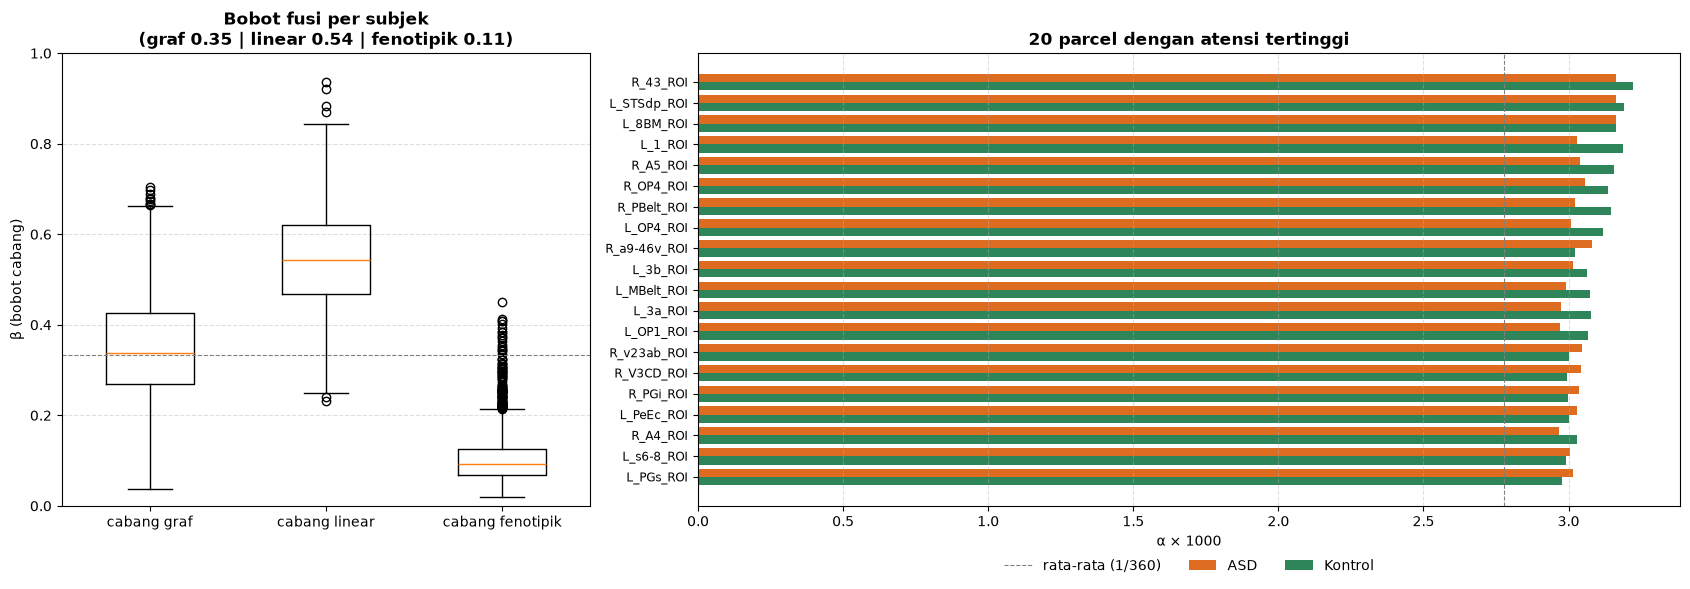

In [17]:
beta = pd.DataFrame(HASIL["beta"], columns=["graf", "linear", "fenotipik"])
alpha = HASIL["alpha"]
rata_alpha = alpha.mean(0)
top = np.argsort(rata_alpha)[::-1][:20]
tab_roi = pd.DataFrame({"Parcel HCP": NAMA_PARCEL[top], "α rata-rata (×1000)": rata_alpha[top] * 1000,
                        "α ASD (×1000)": alpha[y == 1][:, top].mean(0) * 1000, "α Kontrol (×1000)": alpha[y == 0][:, top].mean(0) * 1000,
                        "Kali dari rata-rata": rata_alpha[top] * N_SIMPUL})
display(tab_roi.round(3).reset_index(drop=True).style.set_caption("20 parcel dengan bobot atensi tertinggi"))
tab_roi.to_csv(TABEL_DIR / "27_S3_parcel_atensi_tertinggi.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [0.7, 1.3]})
axes[0].boxplot([beta["graf"], beta["linear"], beta["fenotipik"]], tick_labels=["cabang graf", "cabang linear", "cabang fenotipik"], widths=0.5)
axes[0].axhline(1 / 3, color="gray", ls="--", lw=0.8)
axes[0].set_ylabel("β (bobot cabang)"); axes[0].set_ylim(0, 1)
axes[0].set_title(f"Bobot fusi per subjek\n(graf {beta['graf'].mean():.2f} | linear {beta['linear'].mean():.2f} | fenotipik {beta['fenotipik'].mean():.2f})", fontweight="bold")
yy = np.arange(len(top))[::-1]
axes[1].barh(yy + 0.2, tab_roi["α ASD (×1000)"], 0.4, color="#DD6B20", label="ASD")
axes[1].barh(yy - 0.2, tab_roi["α Kontrol (×1000)"], 0.4, color="#2F855A", label="Kontrol")
axes[1].axvline(1000 / N_SIMPUL, color="gray", ls="--", lw=0.8, label="rata-rata (1/360)")
axes[1].set_yticks(yy); axes[1].set_yticklabels(tab_roi["Parcel HCP"], fontsize=8.5)
axes[1].set_xlabel("α × 1000"); axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=3, frameon=False); axes[1].set_title("20 parcel dengan atensi tertinggi", fontweight="bold")
for ax in axes:
    ax.grid(axis="x" if ax is axes[1] else "y", alpha=0.4, ls="--")
plt.tight_layout()
fig.savefig(FIG_DIR / "27_6_interpretasi_atensi_s3.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Cara Membaca Hasil

| Pertanyaan | Dilihat dari |
| :--- | :--- |
| Seberapa baik model usulan dengan rs-fMRI + sMRI + fenotipik? | baris **Rata-rata ± SD antar run** di tabel 8.1 |
| **Apakah fenotipik menambah informasi dibanding S2?** | **8.4**: selisih per run, uji t berpasangan, McNemar S2 vs S3. Perhatikan juga kepala bantu cabang fenotipik (8.2) dan bobot β fenotipik (8.8) |
| Seberapa stabil hasilnya bila diulang? | SD antar run (8.1): SD kecil berarti hasil tidak bergantung keberuntungan seed |
| Apakah setara, lebih baik, atau lebih rendah dari LR? | tabel 8.3 (kolom **p Holm** dan **Kesimpulan**) |
| Apakah cabang graf menangkap sinyal sendiri? | kepala bantu cabang graf (8.2): AUC jauh di atas 50% berarti graf belajar pola bermakna |
| Apakah model seimbang antara ASD dan kontrol? | sensitivitas vs spesifisitas, balanced accuracy, confusion matrix |
| Apakah model merata di kedua dataset dan semua situs? | tabel per dataset dan grafik per situs (8.6) |
| Apakah model overfitting? | kurva belajar (8.7): epoch terpilih jauh sebelum akhir pelatihan + AUC validasi stabil |
| Cabang mana yang diandalkan, dan wilayah otak mana yang penting? | β dan α (8.8). Wilayah dengan α tinggi akan dibandingkan dengan literatur ASD di Bab 4 |

Notebook 19 (S4) memakai data, fitur, model, dan fold yang sama dengan S3; yang berubah hanya hyperparameter, yang dicari dengan *Optuna* di setiap fold.

### Kesimpulan

*(Diisi setelah melihat hasil.)*